In [5]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler, StandardScaler



In [6]:
data = {
    "AnnualIncome":[15,10,20,22,25,70,75,78,80,85],
    "SpendingScore":[80,85,70,90,82,20,25,15,22,18]
}
df = pd.DataFrame(data)
print(df)

   AnnualIncome  SpendingScore
0            15             80
1            10             85
2            20             70
3            22             90
4            25             82
5            70             20
6            75             25
7            78             15
8            80             22
9            85             18


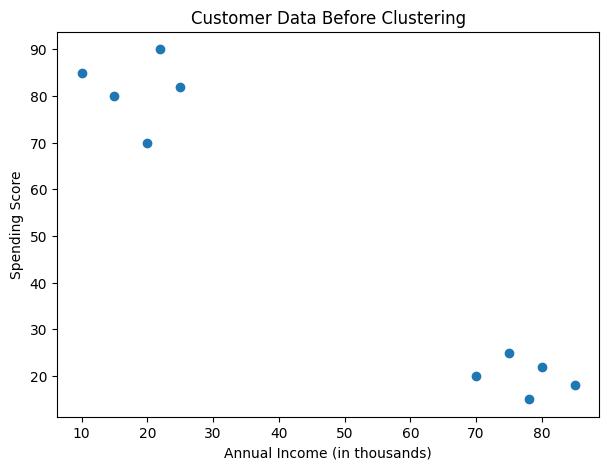

In [7]:
plt.figure(figsize=(7,5))

plt.scatter(
    df["AnnualIncome"],
    df["SpendingScore"]
)
plt.xlabel("Annual Income (in thousands)")
plt.ylabel("Spending Score")
plt.title("Customer Data Before Clustering")
plt.show()

In [8]:
x = df[["AnnualIncome","SpendingScore"]]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(x)
print(X_scaled.round(2))

[[-1.1   0.94]
 [-1.26  1.1 ]
 [-0.93  0.62]
 [-0.87  1.26]
 [-0.77  1.  ]
 [ 0.73 -0.99]
 [ 0.9  -0.83]
 [ 1.   -1.15]
 [ 1.07 -0.92]
 [ 1.23 -1.05]]


In [9]:
kmeans = KMeans(
    n_clusters = 2,
    random_state = 42,
    n_init = 10
)
kmeans.fit(X_scaled)
df["Cluster"] = kmeans.labels_
print(df)

   AnnualIncome  SpendingScore  Cluster
0            15             80        0
1            10             85        0
2            20             70        0
3            22             90        0
4            25             82        0
5            70             20        1
6            75             25        1
7            78             15        1
8            80             22        1
9            85             18        1


In [10]:
centroids_scaled = kmeans.cluster_centers_
centroids_original = scaler.inverse_transform(centroids_scaled)

print("Cluster centroids in original units:")
print(centroids_original.round(2))

Cluster centroids in original units:
[[18.4 81.4]
 [77.6 20. ]]


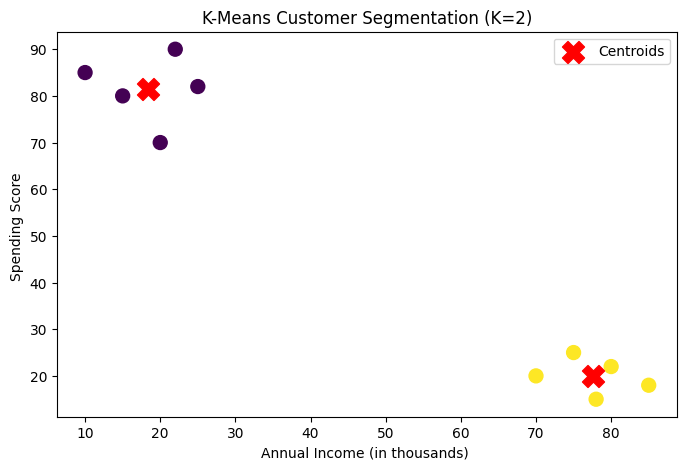

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["AnnualIncome"],
    df["SpendingScore"],
    c=df["Cluster"],
    cmap="viridis",
    s=100
)

plt.scatter(
    centroids_original[:, 0],
    centroids_original[:, 1],
    color="red",
    marker="X",
    s=250,
    label="Centroids"
)

plt.xlabel("Annual Income (in thousands) ")
plt.ylabel("Spending Score ")
plt.title("K-Means Customer Segmentation (K=2)")
plt.legend()
plt.show()

In [12]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

inertia = []
k_range = range(1, 11)


In [13]:
X, y_true = make_blobs(
    n_samples=500, centers=4, cluster_std=0.60, random_state=42
)

inertia = []
k_range = range(1, 11)


for k in k_range:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(X)
  inertia.append(kmeans.inertia_)

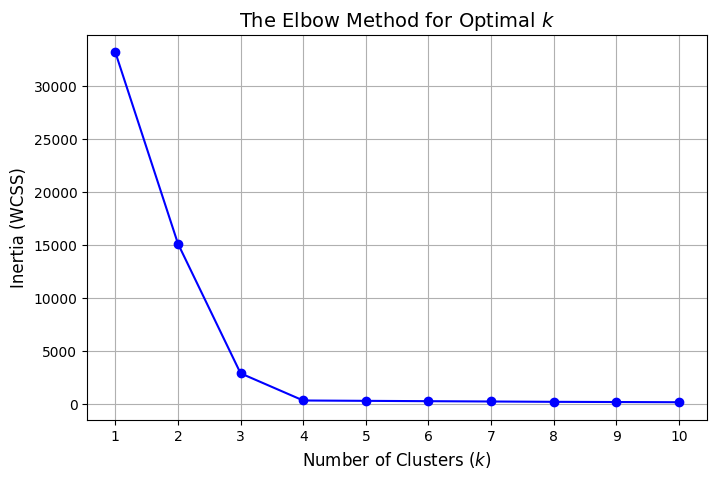

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker="o", linestyle="-", color="b")
plt.title("The Elbow Method for Optimal $k$", fontsize=14)
plt.xlabel("Number of Clusters ($k$)", fontsize=12)
plt.ylabel("Inertia (WCSS)", fontsize=12)
plt.xticks(k_range)
plt.grid(True)
plt.show()